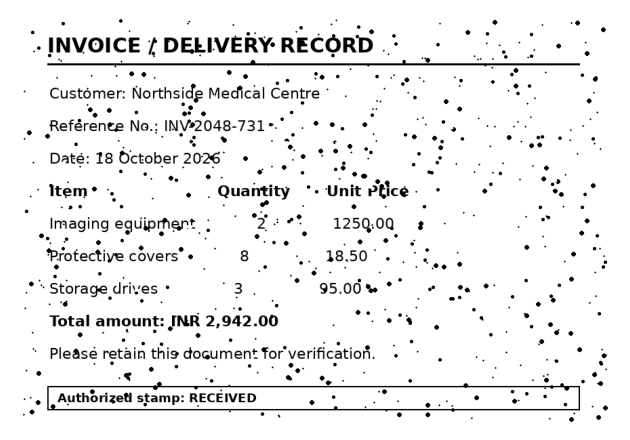

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


image_path = "document_damaged.png"
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

plt.plot(figsize=(20, 5))
plt.imshow(image, cmap="gray")
plt.axis("off")
plt.tight_layout()
plt.show()

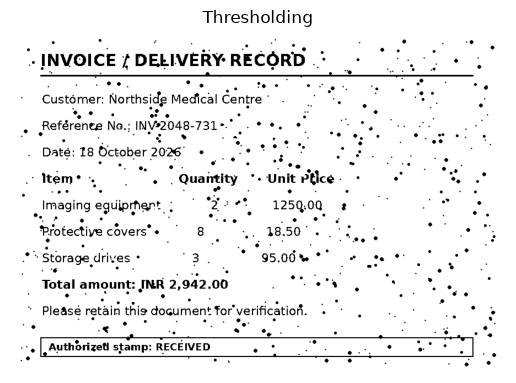

In [8]:
# convert to binary image with some threshold. Show both images

ret, binary_cv = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.imshow(binary_cv, cmap="gray")
plt.title("Thresholding")
plt.axis("off")
plt.show()

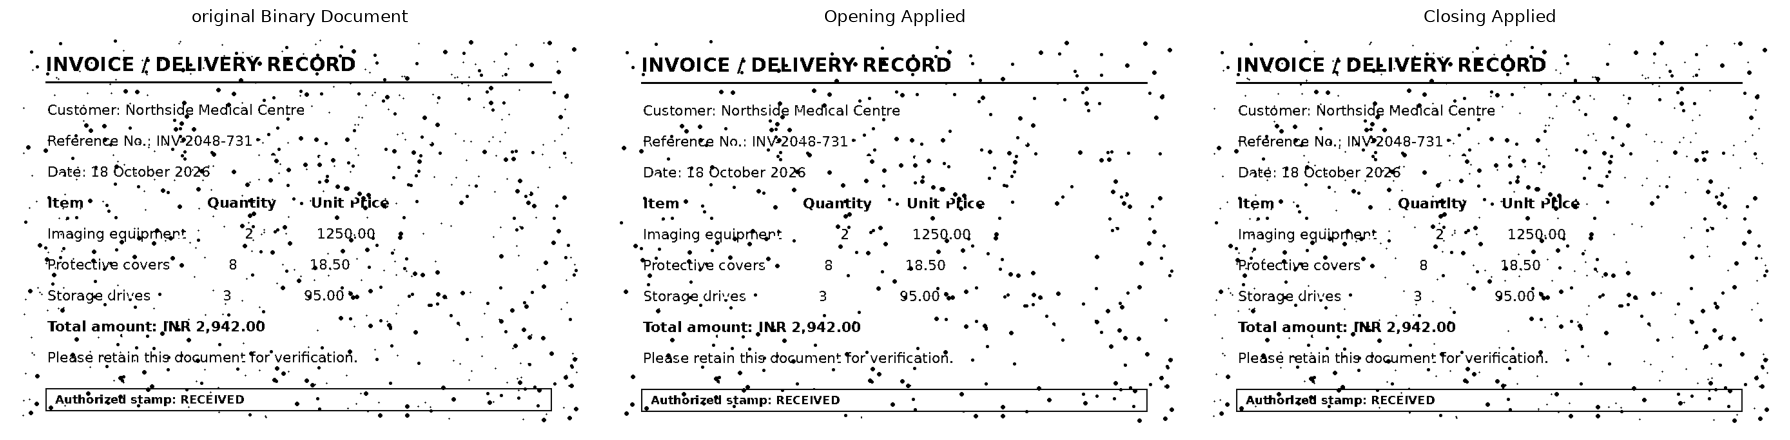

In [ ]:
#invert image so that text is white and everythung ekse us black.

text_inv = cv2.bitwise_not(binary_cv)

kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))

opening = cv2.morphologyEx(text_inv, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(text_inv, cv2.MORPH_CLOSE, kernel)

open_img = cv2.bitwise_not(opening)
closed_img = cv2.bitwise_not(closing)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(binary_cv, cmap="gray")
axes[0].set_title("original Binary Document")

axes[1].imshow(open_img, cmap="gray")
axes[1].set_title("Opening Applied")

axes[2].imshow(closed_img, cmap="gray")
axes[2].set_title("Closing Applied")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

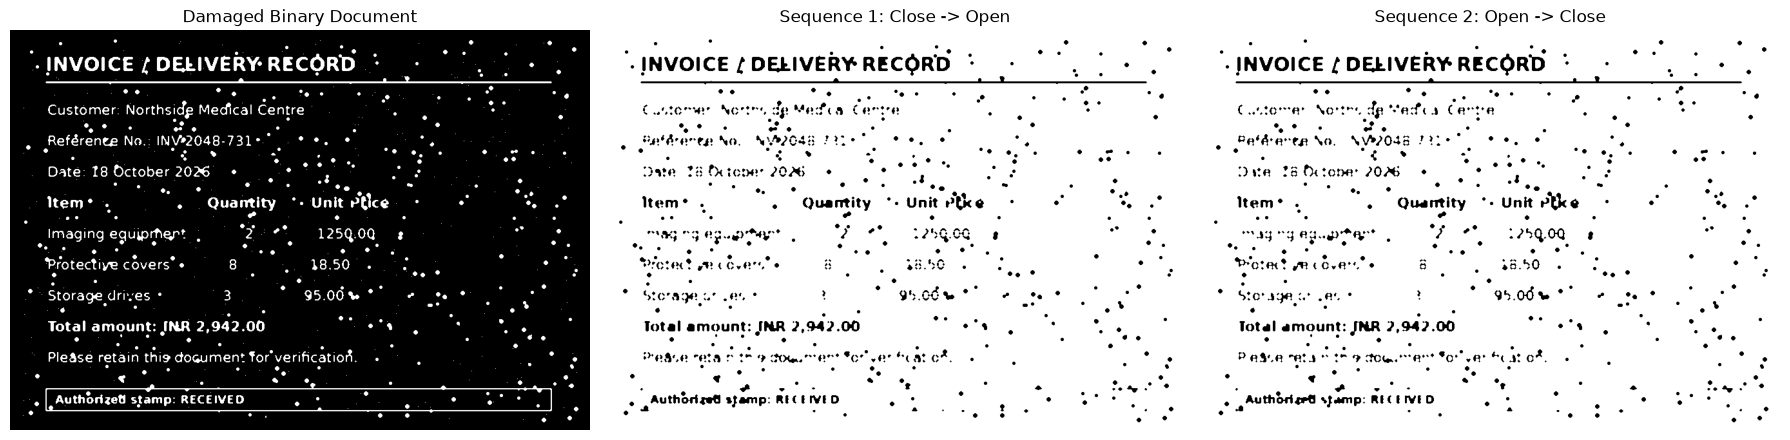

In [16]:
# select sequence of operations that improves document

# Filtering out noise
img_clean = cv2.medianBlur(image, 3)

# Thresholding
ret, binary_cv = cv2.threshold(img_clean, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Structuring element
kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
kernel_open  = cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))

# Sequence A: Close first (repair broken text), then Open (clean isolated noise)
seq_close_then_open = cv2.morphologyEx(binary_cv, cv2.MORPH_CLOSE, kernel_close)
seq_close_then_open = cv2.morphologyEx(seq_close_then_open, cv2.MORPH_OPEN, kernel_open)
restored_A = cv2.bitwise_not(seq_close_then_open)

# Sequence B: Open first (clean noise), then Close (reconnect text)
seq_open_then_close = cv2.morphologyEx(binary_cv, cv2.MORPH_OPEN, kernel_open)
seq_open_then_close = cv2.morphologyEx(seq_open_then_close, cv2.MORPH_CLOSE, kernel_close)
restored_B = cv2.bitwise_not(seq_open_then_close)

# Compare Original vs Restored
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(binary_cv, cmap="gray")
axes[0].set_title("Damaged Binary Document")

axes[1].imshow(restored_A, cmap="gray")
axes[1].set_title("Sequence 1: Close -> Open")

axes[2].imshow(restored_B, cmap="gray")
axes[2].set_title("Sequence 2: Open -> Close")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

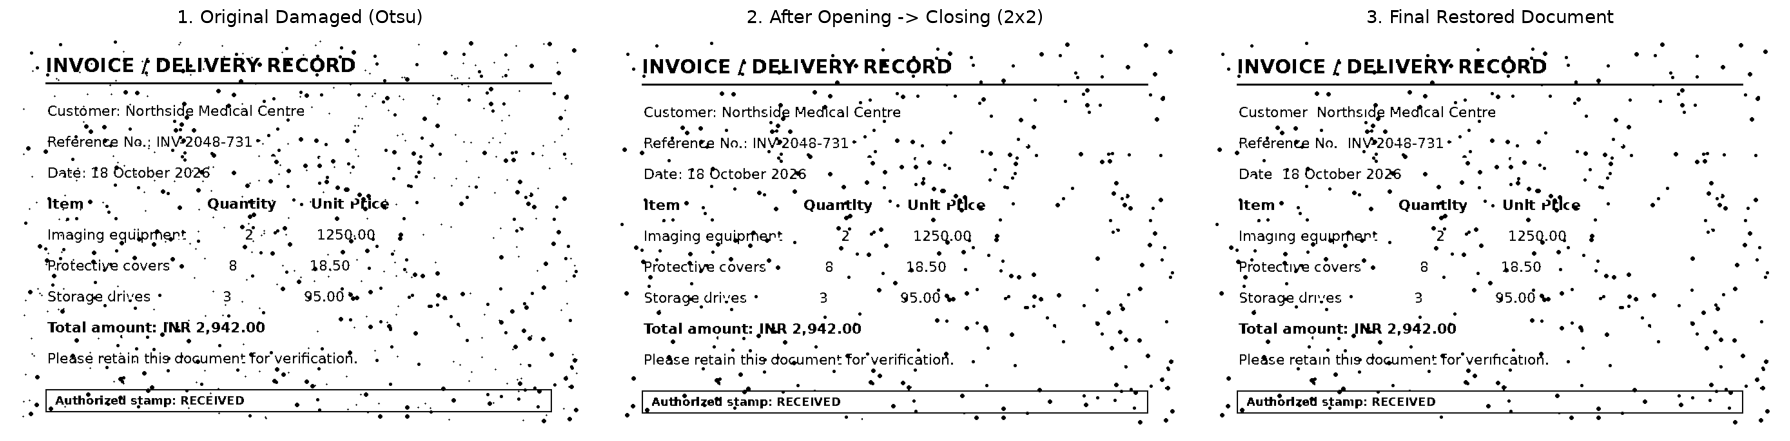

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# 1. Load and Binarize (Invert so Text = White foreground 255)
# -------------------------------------------------------------
gray = cv2.imread("document_damaged.png", cv2.IMREAD_GRAYSCALE)
_, text_fg = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# -------------------------------------------------------------
# 2. Morphological Operations with a 2x2 Kernel
# -------------------------------------------------------------
kernel = np.ones((2, 2), np.uint8)

# Step A: Opening (Erode -> Dilate) strips isolated noise specks
opened = cv2.morphologyEx(text_fg, cv2.MORPH_OPEN, kernel)

# Step B: Closing (Dilate -> Erode) bridges small gaps in the letters
closed = cv2.morphologyEx(opened, cv2.MORPH_CLOSE, kernel)

# -------------------------------------------------------------
# 3. Optional Polish: Connected Component Area Filter
# Removes any stubborn noise specks (< 8 px); periods/dots are >= 16 px
# -------------------------------------------------------------
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(closed)
clean_text = np.zeros_like(closed)

min_area = 8  # noise threshold
for i in range(1, num_labels):
    if stats[i, cv2.CC_STAT_AREA] >= min_area:
        clean_text[labels == i] = 255

# -------------------------------------------------------------
# 4. Invert Back to Standard View (Black text on White background)
# -------------------------------------------------------------
final_document = cv2.bitwise_not(clean_text)

# -------------------------------------------------------------
# 5. Visual Comparison
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

# Original binary
axes[0].imshow(cv2.bitwise_not(text_fg), cmap="gray")
axes[0].set_title("1. Original Damaged (Otsu)", fontsize=13)

# Intermediate: After Open -> Close
axes[1].imshow(cv2.bitwise_not(closed), cmap="gray")
axes[1].set_title("2. After Opening -> Closing (2x2)", fontsize=13)

# Final Clean Document
axes[2].imshow(final_document, cmap="gray")
axes[2].set_title("3. Final Restored Document", fontsize=13)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()